# Gerçek zamanlı oturum takibi

Bu defter yeni cevap olaylarını gerçek alım saatleriyle kaydeder. Oturum boş
başlar; ASSIST2009 öğrencisinin geçmişi yeni katılımcıya aktarılmaz. Mevcut
sorunun doğruluğu dışarıda değerlendirilip doğru veya yanlış olarak girilir.
Kaynak veri soru metni içermediğinden seçim mevcut soru kimliğiyle yapılır.
Yeni soru bankası hazırlanmaz ve model yeniden eğitilmez.

Aşağıdaki kayıtlar gerçek saat çağrılarıyla çalışan **otomatik işlev testidir**;
insan öğrenme verisi veya öğrenme kazanımı deneyi değildir. En alttaki ekran
elle girilecek değerlendirilmiş cevapları kaydetmek için kullanılabilir.

In [1]:
from pathlib import Path
import inspect
import json
import os
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image, Code

ROOT=Path.cwd().resolve()
if not (ROOT / "src/kt_project").exists():
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".runtime/matplotlib"))
os.environ.setdefault("PYTHONUTF8","1")
import torch
torch.set_num_threads(4)
def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))
if not (ROOT/"outputs/live/demo_session.json").exists():
    subprocess.run([sys.executable,str(ROOT/"scripts/run_live_session_demo.py")],cwd=ROOT,check=True)
record=read(ROOT/"outputs/live/demo_session.json")
assert record["response_origin"]=="automated_smoke_test"
print("Örnek kaydın türü:",record["response_origin"])
print("Başlangıç geçmişi:",record["initial_history_count"])
print("Başlangıç zamanı UTC:",record["created_at"])

Örnek kaydın türü: automated_smoke_test
Başlangıç geçmişi: 0
Başlangıç zamanı UTC: 2026-11-15T22:13:26.136059+00:00


## Cevaptan önce tahmin ve kalıcı kayıt

Soruyu başlatma çağrısı yalnızca soru kimliğini alır; hedef cevabı almaz.
Bekleyen soru geçmişe eklenmez. Sonuç girilince zaman damgası ve süre
kaydedilir; ardından geçmiş ve göstergeler güncellenir. Aynı cevap kimliği
iki kez gönderilirse geçmişe ikinci kayıt eklenmez. Oturum diske atomik
olarak yazılır; kimliğiyle yeniden açılabilir. İçerik özeti ve olay zinciri
kazara değişmiş kayıtları tespit eder; kriptografik kimlik doğrulama değildir.

In [2]:
from kt_project.live_session import LiveResources,LiveSession,parse_time
from kt_project.live_ui import event_table,create_live_controls
display(Code(inspect.getsource(LiveSession.prepare),language="python"))
display(Code(inspect.getsource(LiveSession.answer),language="python"))
display(event_table(record).round(3))
assert all(event["history_count_before"]==index for index,event in enumerate(record["events"]))
assert all(parse_time(event["predicted_at"])<=parse_time(event["answer_received_at"])
           <=parse_time(event["state_updated_at"]) for event in record["events"])

def prepare(self, original_problem_id):
        with self._lock:
            if self.data["status"] != "open" or self.data["pending"] is not None:
                raise ValueError("Oturum kapalı veya tamamlanmamış bir soru var.")
            if isinstance(original_problem_id, bool) or not isinstance(original_problem_id, (int, np.integer)):
                raise ValueError("Soru kimliği tam sayı olmalı.")
            inverse = {value: key for key, value in self.resources.inverse_questions.items()}
            encoded = inverse.get(int(original_problem_id))
            if encoded not in self.resources.catalog:
                raise ValueError("Eğitimden bilinen bir soru seçilmeli.")
            question = {key: self.resources.catalog[encoded][key] for key in ("question", "skills", "difficulty")}
            started = self._ordered_now()
            snap = snapshot_for(self.store, 0, len(self.data["events"]))
            probability = float(self.tracer.predict_requests([(snap, question)], self.resources.config["prediction_batch_size"])[0])
            if not np.isfinite(probability) or not 0 <= probability <= 1:
                raise ValueError("Geçersiz model olasılığı.")
            now = self._ordered_now()
            if parse_time(now) < parse_time(started):
                raise ValueError("Tahmin sırasında sistem saati geriye gitti.")
            pending = {"question_token": uuid.uuid4().hex, "question": copy.deepcopy(question),
                "original_problem_id": int(original_problem_id), "history_count_before": len(self.data["events"]),
                "prediction_started_at": started, "predicted_at": now, "presented_at": now,
                "predicted_correct_probability": probability}
            self.data["pending"] = pending
            self._pending_tick = self._monotonic()
            try:
                self._persist()
            except Exception:
                self.data["pending"] = None
                self._pending_tick = None
                raise
            return copy.deepcopy(pending)

def answer(self, question_token, correct, hint_count=0):
        with self._lock:
            if isinstance(correct, bool) or not isinstance(correct, (int, np.integer)) or correct not in (0,1):
                raise ValueError("Değerlendirilmiş cevap 0 veya 1 olmalı.")
            if isinstance(hint_count, bool) or not isinstance(hint_count, (int,np.integer)) or not 0 <= hint_count <= 100:
                raise ValueError("İpucu sayısı 0 ile 100 arasında tam sayı olmalı.")
            for event in self.data["events"]:
                if event["question_token"] == question_token:
                    if event["correct"] != correct or event["hint_count"] != hint_count:
                        raise ValueError("Aynı cevap kaydı farklı sonuçla yeniden gönderilemez.")
                    return copy.deepcopy(event)
            pending = self.data["pending"]
            if self.data["status"] != "open" or pending is None or pending["question_token"] != question_token:
                raise ValueError("Cevap, açık bekleyen soruya ait değil.")
            received = self._ordered_now()
            seconds = (self._monotonic()-self._pending_tick) if self._pending_tick is not None else (
                parse_time(received)-parse_time(pending["presented_at"])).total_seconds()
            if not np.isfinite(seconds) or seconds < 0:
                raise ValueError("Geçersiz cevap süresi.")
            event = {**copy.deepcopy(pending), "sequence": len(self.data["events"])+1,
                "answer_received_at": received, "correct": int(correct), "hint_count": int(hint_count),
                "response_duration_seconds": float(seconds),
                "duration_clock": "monotonic" if self._pending_tick is not None else "UTC_after_resume",
                "response_origin": self.data["response_origin"],
                "previous_event_sha256": self.data["events"][-1]["event_sha256"] if self.data["events"] else "initial"}
            candidate = self.data["events"]+[event]
            old_skills = list(self.data["tracked_skills"])
            try:
                for skill in event["question"]["skills"]:
                    if self.resources.bank.has_skill(skill) and skill not in self.data["tracked_skills"]:
                        self.data["tracked_skills"].append(skill)
                self._sync(candidate)
                event["after"] = self._state()
                event["state_updated_at"] = self._now()
                if parse_time(event["state_updated_at"]) < parse_time(received):
                    raise ValueError("Güncelleme sırasında sistem saati geriye gitti.")
                event["event_sha256"] = content_hash(event)
                self.data["events"].append(event)
                self.data["pending"] = None
                self._persist()
            except Exception:
                self.data["tracked_skills"] = old_skills
                if self.data["events"] and self.data["events"][-1] is event:
                    self.data["events"].pop()
                self.data["pending"] = pending
                self._sync(self.data["events"])
                raise
            self._pending_tick = None
            return copy.deepcopy(event)

,Cevap,Mevcut soru,Tahmin %,Doğru (1/0),Tahmin saati,Cevap alım saati,Cevap süresi sn,Kaynak
0,1,53833,81.287,1,2026-11-16T01:13:27.010+03:00,2026-11-16T01:13:27.170+03:00,0.160,automated_smoke_test
1,2,53983,38.676,0,2026-11-16T01:13:27.221+03:00,2026-11-16T01:13:27.530+03:00,0.309,automated_smoke_test
2,3,42492,38.723,0,2026-11-16T01:13:27.577+03:00,2026-11-16T01:13:28.084+03:00,0.507,automated_smoke_test
3,4,53834,71.223,1,2026-11-16T01:13:28.152+03:00,2026-11-16T01:13:28.314+03:00,0.163,automated_smoke_test
4,5,53987,36.659,1,2026-11-16T01:13:28.376+03:00,2026-11-16T01:13:28.688+03:00,0.311,automated_smoke_test
5,6,44718,42.012,1,2026-11-16T01:13:28.831+03:00,2026-11-16T01:13:29.291+03:00,0.460,automated_smoke_test


## Gerçek zaman ekseni ve son değeri tutma

Yatay eksen gerçek kayıt zamanıdır. Her cevaptan sonra yeni model tahmini
hesaplanır. İki olay arasında son tahmin tutulur; araya yapay öğrenme değeri
eklenmez. İlk cevap öncesinde gözlenen doğru oranı yoktur. Davranış grubu
en az beş yeni cevaptan sonra gösterilir. Geçen süre, KT modelinin yeni bir
girdisi değildir; burada zamanla unutma modeli eğitilmemiştir.

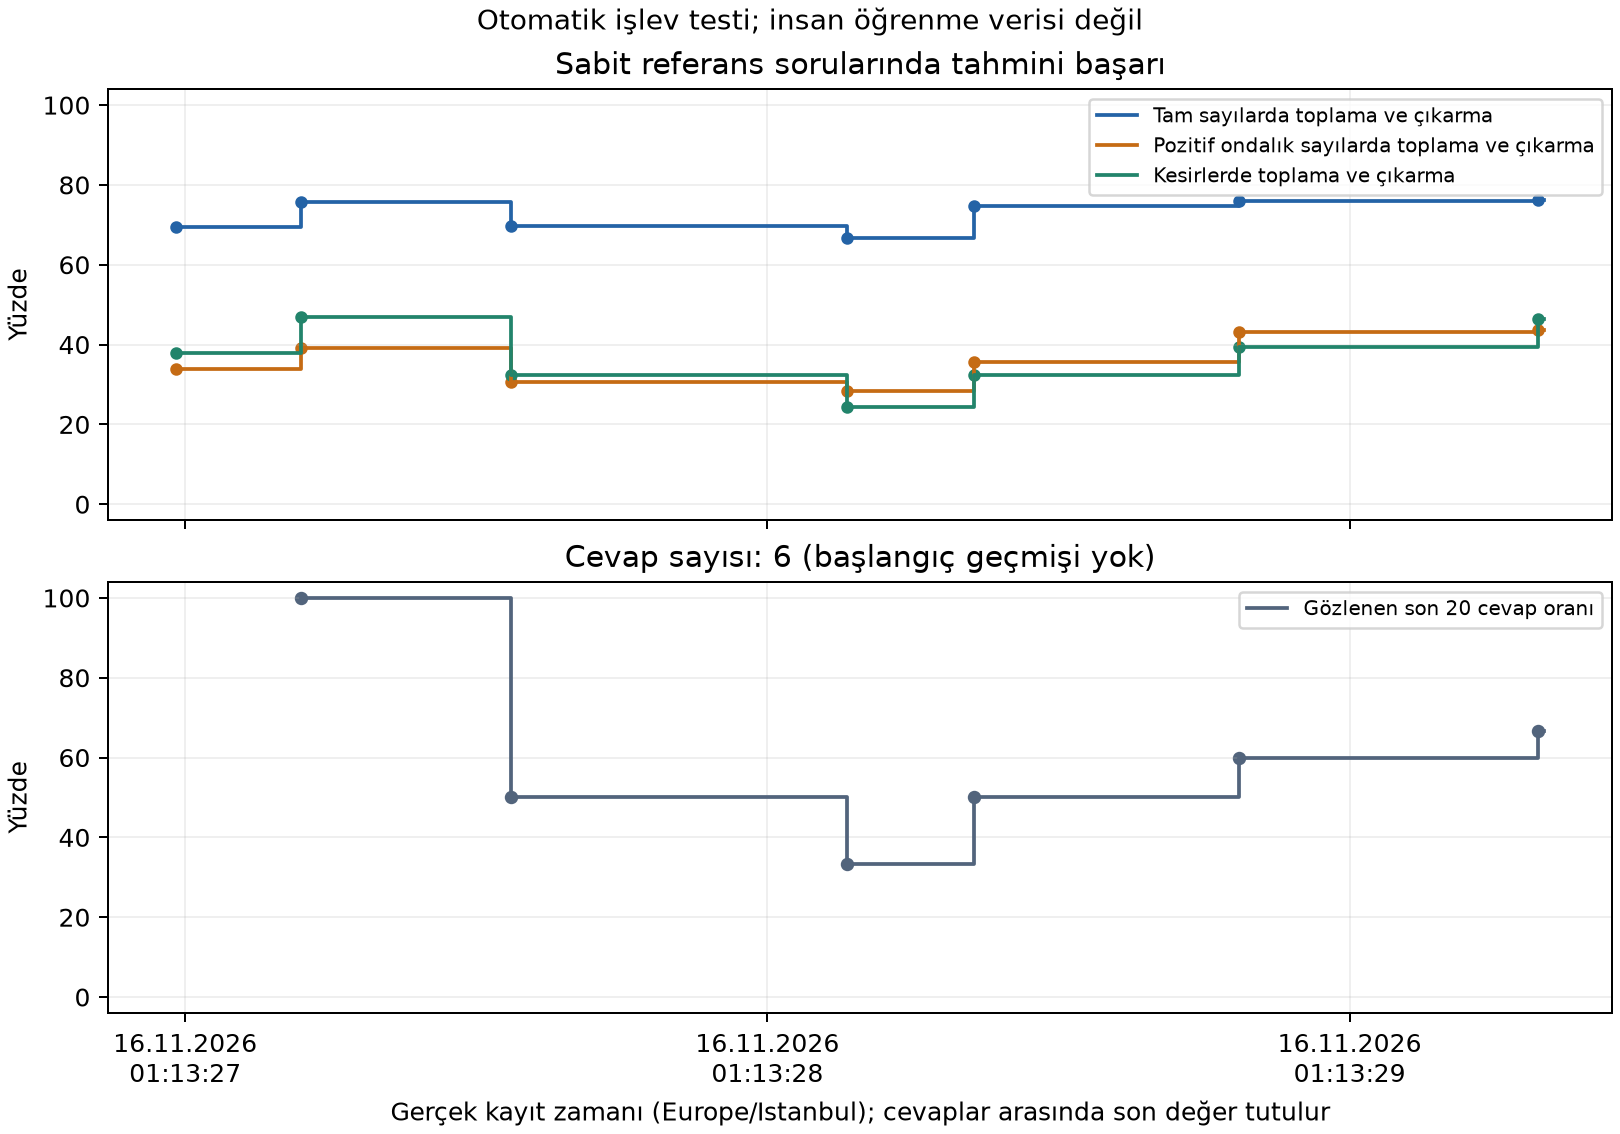

,skill,name,predicted_success_percent,observed_correct_percent,recent_skill_answers,reference_question_count
0,81,Tam sayılarda toplama ve çıkarma,69.472140,None,0,32
1,82,Pozitif ondalık sayılarda toplama ve çıkarma,33.923542,None,0,32
2,84,Kesirlerde toplama ve çıkarma,38.006216,None,0,32


,skill,name,predicted_success_percent,observed_correct_percent,recent_skill_answers,reference_question_count
0,81,Tam sayılarda toplama ve çıkarma,76.327157,100.0,2,32
1,82,Pozitif ondalık sayılarda toplama ve çıkarma,43.676925,50.0,2,32
2,84,Kesirlerde toplama ve çıkarma,46.427974,50.0,2,32


source                                        actual local wall-clock calls with explicitly ...
human_learning_study                                                                      False
record_file                                   outputs/live/sessions/0b18200292ca47faba11ab88...
events                                                                                        6
initial_history_count                                                                         0
resume_verified                                                                            True
source_event_times_fabricated                                                             False
timestamped_response_recording_implemented                                                 True
elapsed_session_seconds                                                                3.197967
each_prediction_precedes_answer                                                            True
all_resource_checks                     

In [3]:
display(Image(filename=str(ROOT/"outputs/live/live_timeline.png")))
display(pd.DataFrame(record["initial_state"]["skill_scores"]))
display(pd.DataFrame(record["events"][-1]["after"]["skill_scores"]))
display(pd.Series(read(ROOT/"outputs/validation/live_session_integrity.json")))

## Elle kullanılabilen oturum ekranı

1. Katılımcı etiketiyle yeni oturum açın. Oturum kimliğini saklayın.
2. Beceri ve mevcut soru kimliğini seçip **Soruyu başlat** düğmesine basın.
3. Sorunun değerlendirilmiş sonucunu doğru veya yanlış olarak kaydedin.
   Bu düğmeler cevap doğruluğunu otomatik ölçmez.
4. Göstergeyi ve gerçek saat grafiğini inceleyin; diğer soruyla devam edin.
5. İş bitince oturumu kapatın. Sonradan oturum kimliğiyle kaydı açabilirsiniz.

Canlı kayıtlar outputs/live/sessions klasöründe ayrı tutulur; eğitim,
doğrulama ve test dosyaları değişmez. Aynı oturumu tek açık çalışma
görünümünde yönetin. Eski bir görünüm güncel kaydın üstüne yazamaz.

In [4]:
resources=LiveResources.load(ROOT)
# Normal kullanımda elle değerlendirilmiş cevap kaydı seçilir. Arayüz test
# süreci kendi ortamında otomatik kaynak etiketini açıkça verir.
origin=os.environ.get("KT_LIVE_RESPONSE_ORIGIN","manual_assessed_response")
live_panel=create_live_controls(resources,origin=origin)
display(live_panel)

## İşlev testleri ve sınırlar

Sabit test saatleri kullanan birim testleri kayıt mekanizmasını doğrular;
gösterilen örnek oturumun saatleri ise gerçek duvar saatinden alınmıştır.
Otomatik test cevapları insan cevabı olarak etiketlenmez. Gerçek katılımcı
verisiyle uzun süreli öğrenme veya öneri etkisi çalışması yapılmamıştır.

Davranış grubu için en az 5 cevap gerekir.
Önerilen mevcut soru: 104
A: izlenen beceriler arasında referans başarı tahmini en düşük olan beceri; sabit referans başarı tahmini %52.6. orta düzeyde zorlayıcı başarı hedefi. Seçilen soruda tahmin %52.6, hedef %65.
Davranış grubu için en az 5 cevap gerekir.
Önerilen mevcut soru: 104
A: izlenen beceriler arasında referans başarı tahmini en düşük olan beceri; sabit referans başarı tahmini %52.6. orta düzeyde zorlayıcı başarı hedefi. Seçilen soruda tahmin %52.6, hedef %65.
Davranış grubu için en az 5 cevap gerekir.
Önerilen mevcut soru: 110
A: izlenen beceriler arasında referans başarı tahmini en düşük olan beceri; sabit referans başarı tahmini %52.4. orta düzeyde zorlayıcı başarı hedefi. Seçilen soruda tahmin %52.5, hedef %65.
Davranış grubu için en az 5 cevap gerekir.
Önerilen mevcut soru: 110
A: izlenen beceriler arasında referans başarı tahmini en düşük olan beceri; sabit referans başarı tahmini %52.4. orta düzeyde zorlayıcı başarı hedefi. 

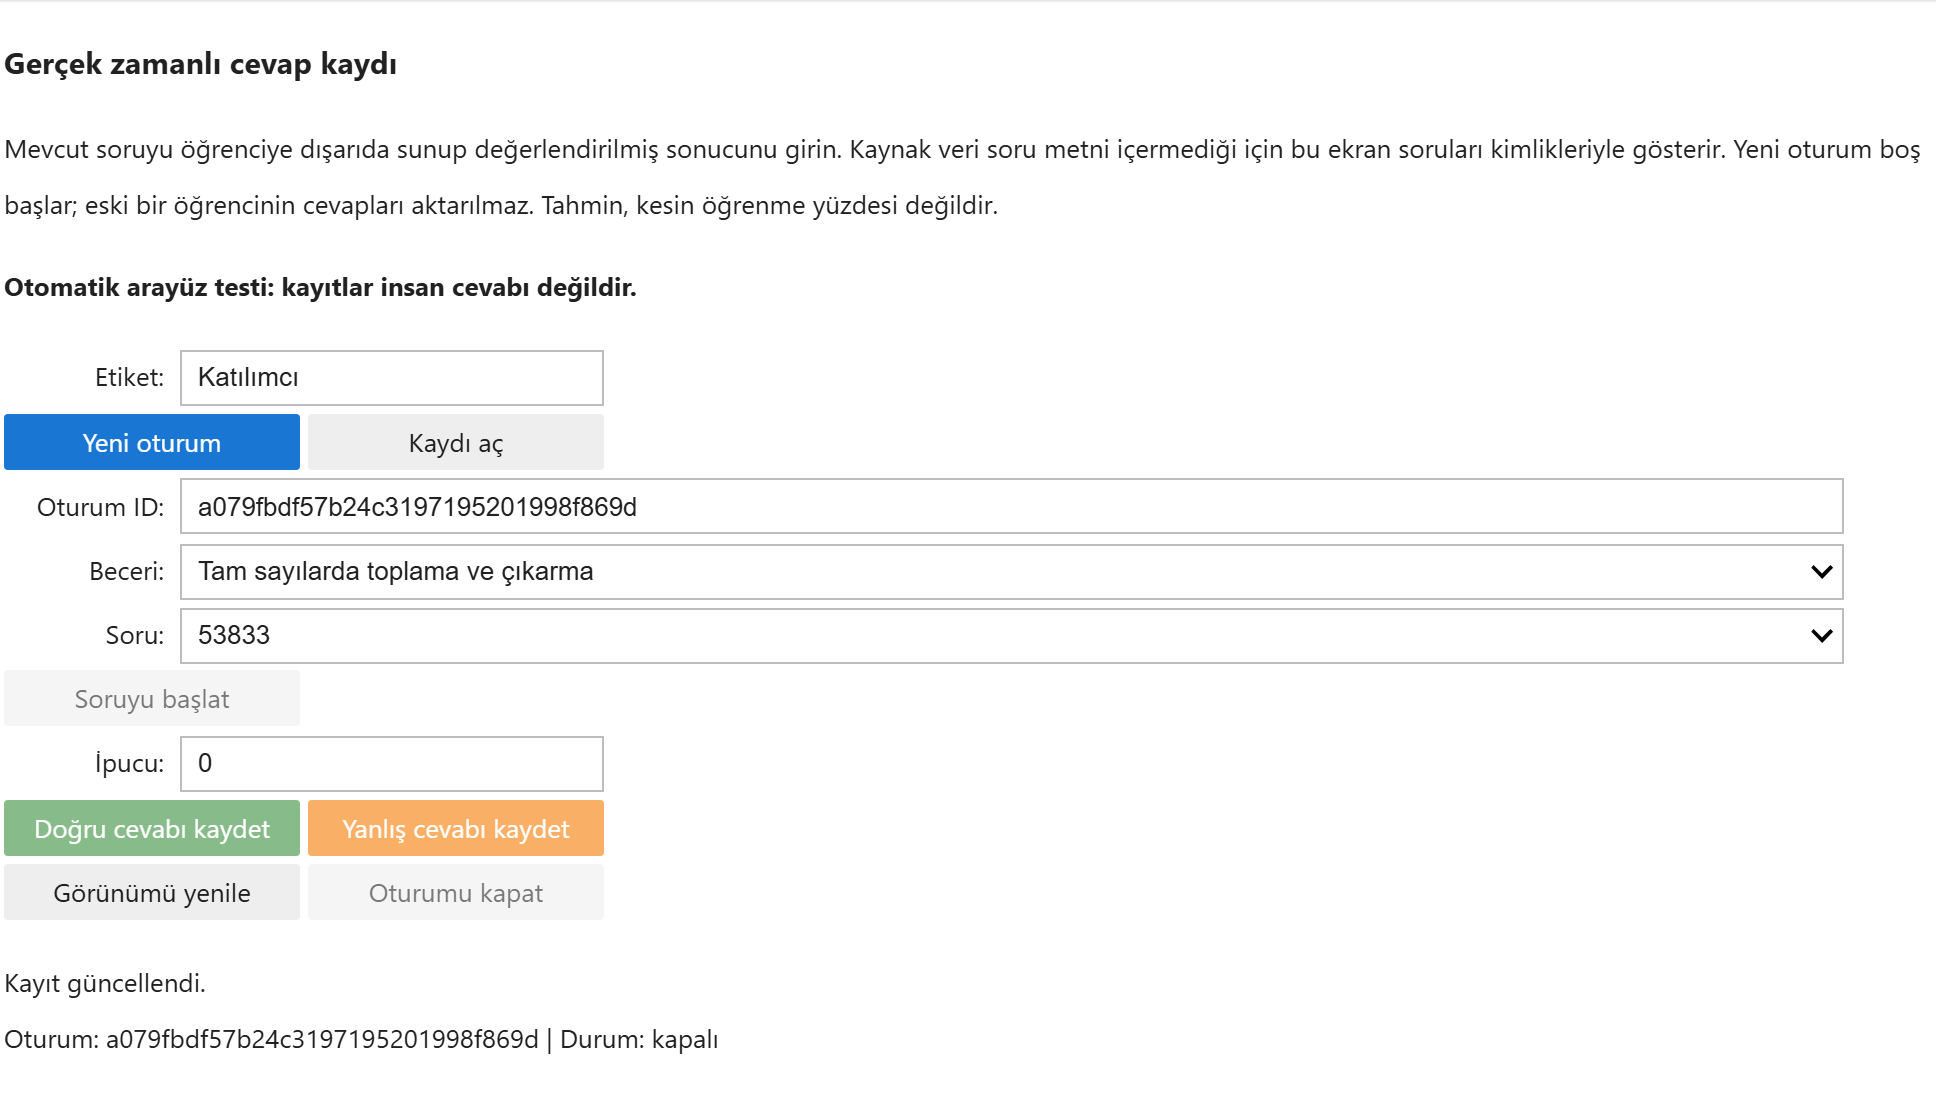

In [5]:
completed=subprocess.run([sys.executable,"-m","unittest","discover","-s","tests",
    "-p","test_live_session.py","-v"],cwd=ROOT,capture_output=True,text=True,
    encoding="utf-8",errors="replace")
print(completed.stdout+completed.stderr)
completed.check_returncode()
if (ROOT/"outputs/live/live_controls.png").exists():
    print("Aşağıdaki görüntü, otomatik kaynak etiketiyle gerçek Jupyter arayüzü kontrolünden alınmıştır.")
    display(Image(filename=str(ROOT/"outputs/live/live_controls.png")))